# Day 080 | Attention Mechanism & Transformers Intro

## 100 Days of ML for Geotechnical Engineering
**Phase:** Deep Learning | **Author:** Ripon Chandra Malo | **Date:** YYYY-MM-DD

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| Self-attention | Each position attends to all others | Each CPT depth attends to all other depths |
| Query, Key, Value | Attention computation triplet | What to look for, what is available, what to return |
| Positional encoding | Inject sequence order information | Encode depth position in CPT profile |
| Multi-head attention | Multiple attention patterns in parallel | Attend to different soil property relationships |
| Transformer encoder | Self-attention + feedforward stack | Process entire CPT profile at once |
| Attention weights | Which positions influence a prediction | Which depths most influence soil classification |

---

## Our Geotechnical Problem

We will build a **Transformer encoder** to process **Cone Penetration Test (CPT) profiles** and predict
the soil type at each depth. Unlike RNNs that process sequentially, Transformers see all depths at once.

```
  CPT Profile Input:              Transformer Output:
  ─────────────────              ──────────────────
  Depth 0.5m: qc=2, fs=0.1      -> Clay
  Depth 1.0m: qc=3, fs=0.15     -> Clay
  Depth 1.5m: qc=8, fs=0.08     -> Sand
  Depth 2.0m: qc=12, fs=0.05    -> Sand
  Depth 2.5m: qc=4, fs=0.2      -> Clay
  ...                            -> ...
  
  Self-attention lets each depth "look at" all other depths
  to understand the full soil profile context.
```

## Part 1: Import Libraries and Generate Synthetic CPT Data

In [1]:
# ───────────────────────────────────────────────────────
# IMPORTS AND SYNTHETIC CPT DATA GENERATION
# ───────────────────────────────────────────────────────

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

def generate_cpt_profiles(n_profiles=200, seq_len=30):
    """
    Generate synthetic CPT profiles with soil type labels.
    
    Features per depth: [qc (MPa), fs (kPa), Rf (%), u2 (kPa)]
    Labels: 0=Clay, 1=Sand, 2=Silt
    """
    profiles = []
    labels = []
    
    for _ in range(n_profiles):
        profile = np.zeros((seq_len, 4))  # qc, fs, Rf, u2
        label = np.zeros(seq_len, dtype=int)
        
        # Generate layered soil profile
        depth = 0
        while depth < seq_len:
            # Random layer thickness
            thickness = np.random.randint(3, 12)
            soil_type = np.random.choice([0, 1, 2])  # Clay, Sand, Silt
            
            end = min(depth + thickness, seq_len)
            
            if soil_type == 0:  # Clay
                profile[depth:end, 0] = np.random.uniform(0.5, 4.0, end - depth)   # qc
                profile[depth:end, 1] = np.random.uniform(10, 80, end - depth)      # fs
                profile[depth:end, 2] = np.random.uniform(2.0, 8.0, end - depth)    # Rf
                profile[depth:end, 3] = np.random.uniform(50, 300, end - depth)     # u2
            elif soil_type == 1:  # Sand
                profile[depth:end, 0] = np.random.uniform(5.0, 25.0, end - depth)
                profile[depth:end, 1] = np.random.uniform(5, 40, end - depth)
                profile[depth:end, 2] = np.random.uniform(0.1, 1.5, end - depth)
                profile[depth:end, 3] = np.random.uniform(-10, 50, end - depth)
            else:  # Silt
                profile[depth:end, 0] = np.random.uniform(2.0, 8.0, end - depth)
                profile[depth:end, 1] = np.random.uniform(15, 60, end - depth)
                profile[depth:end, 2] = np.random.uniform(1.0, 4.0, end - depth)
                profile[depth:end, 3] = np.random.uniform(20, 150, end - depth)
            
            label[depth:end] = soil_type
            depth = end
        
        profiles.append(profile)
        labels.append(label)
    
    return np.array(profiles), np.array(labels)

X_data, y_data = generate_cpt_profiles(n_profiles=200, seq_len=30)

print(f"CPT profiles shape: {X_data.shape}  (n_profiles, seq_len, features)")
print(f"Labels shape:       {y_data.shape}  (n_profiles, seq_len)")
print(f"\nFeatures: qc (MPa), fs (kPa), Rf (%), u2 (kPa)")
print(f"Classes: 0=Clay, 1=Sand, 2=Silt")
print(f"\nClass distribution: Clay={np.mean(y_data==0):.1%}, Sand={np.mean(y_data==1):.1%}, Silt={np.mean(y_data==2):.1%}")

CPT profiles shape: (200, 30, 4)  (n_profiles, seq_len, features)
Labels shape:       (200, 30)  (n_profiles, seq_len)

Features: qc (MPa), fs (kPa), Rf (%), u2 (kPa)
Classes: 0=Clay, 1=Sand, 2=Silt

Class distribution: Clay=32.2%, Sand=35.5%, Silt=32.3%


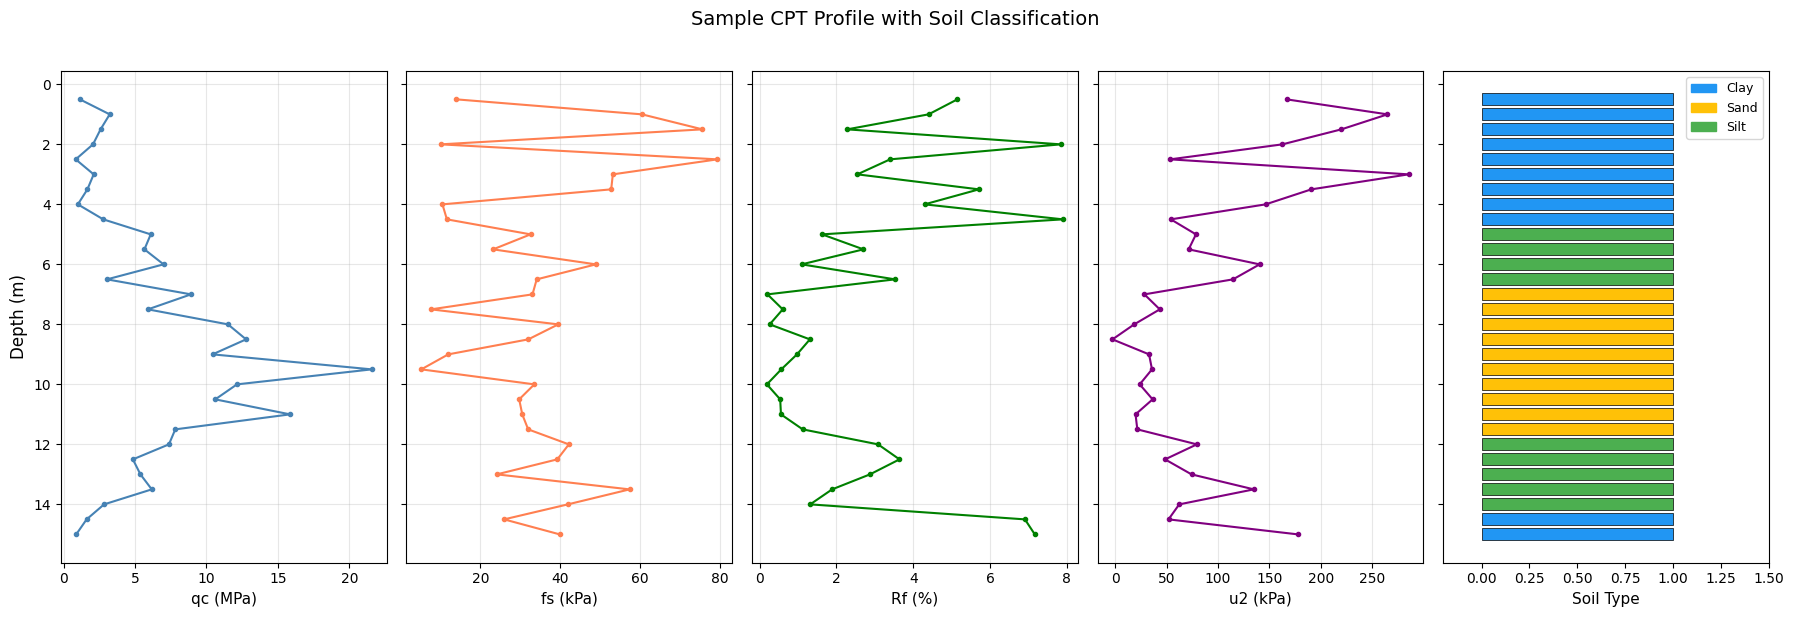

In [2]:
# ───────────────────────────────────────────────────────
# VISUALIZE A SAMPLE CPT PROFILE
# ───────────────────────────────────────────────────────

idx = 0
depths = np.arange(X_data.shape[1]) * 0.5 + 0.5  # 0.5m intervals

fig, axes = plt.subplots(1, 5, figsize=(18, 6), sharey=True)

feature_names = ['qc (MPa)', 'fs (kPa)', 'Rf (%)', 'u2 (kPa)']
colors_feat = ['steelblue', 'coral', 'green', 'purple']

for i, (name, color) in enumerate(zip(feature_names, colors_feat)):
    axes[i].plot(X_data[idx, :, i], depths, '-o', color=color, markersize=3, linewidth=1.5)
    axes[i].set_xlabel(name, fontsize=11)
    axes[i].grid(True, alpha=0.3)
    if i == 0:
        axes[i].set_ylabel('Depth (m)', fontsize=12)

# Soil type column
soil_colors = {0: '#2196F3', 1: '#FFC107', 2: '#4CAF50'}
soil_names = {0: 'Clay', 1: 'Sand', 2: 'Silt'}
for d_idx in range(len(depths)):
    axes[4].barh(depths[d_idx], 1, height=0.4,
                 color=soil_colors[y_data[idx, d_idx]], edgecolor='k', linewidth=0.5)
axes[4].set_xlabel('Soil Type', fontsize=11)
axes[4].set_xlim(-0.2, 1.5)

import matplotlib.patches as mpatches
legend_patches = [mpatches.Patch(color=soil_colors[k], label=soil_names[k]) for k in [0, 1, 2]]
axes[4].legend(handles=legend_patches, fontsize=9)

axes[0].invert_yaxis()
plt.suptitle('Sample CPT Profile with Soil Classification', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

---

## Part 2: Self-Attention from Scratch

Self-attention computes:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^T}{\sqrt{d_k}}\right) V$$

- **Q** (Query): What am I looking for?
- **K** (Key): What do I have to offer?
- **V** (Value): What information do I carry?

Input shape:            (30, 4)  (seq_len, features)
Attention weights:      (30, 30)  (seq_len, seq_len)
Output shape:           (30, 8)  (seq_len, d_k)

Each row of attention weights sums to 1.0:
  Row 0 sum: 1.0000
  Row 15 sum: 1.0000


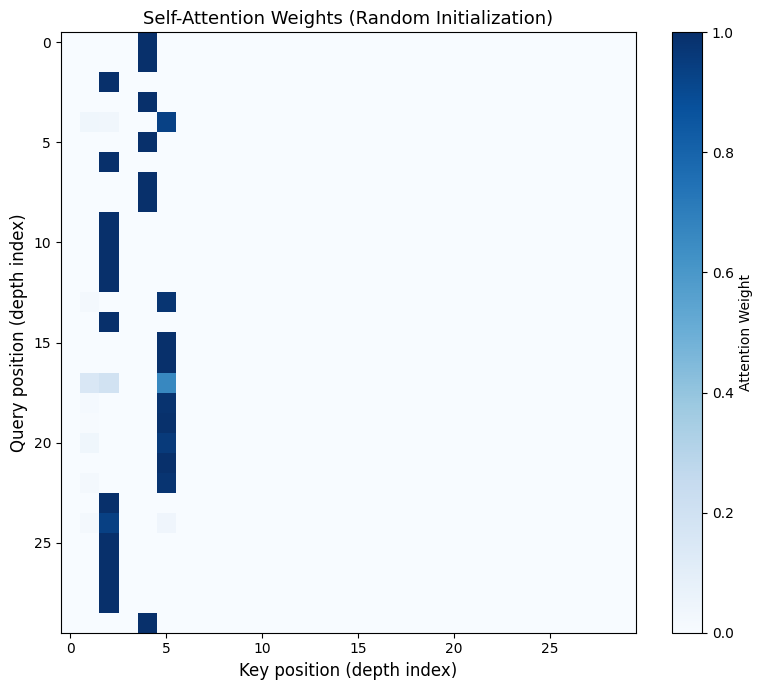

After training, attention weights reveal which depths attend to which.


In [3]:
# ───────────────────────────────────────────────────────
# SELF-ATTENTION FROM SCRATCH
# ───────────────────────────────────────────────────────

def self_attention(X, W_q, W_k, W_v):
    """
    Compute self-attention manually.
    
    X: (seq_len, d_model) — input sequence
    W_q, W_k, W_v: (d_model, d_k) — projection matrices
    """
    Q = X @ W_q   # (seq_len, d_k)
    K = X @ W_k   # (seq_len, d_k)
    V = X @ W_v   # (seq_len, d_k)
    
    d_k = Q.shape[1]
    
    # Attention scores: Q @ K^T / sqrt(d_k)
    scores = Q @ K.T / np.sqrt(d_k)   # (seq_len, seq_len)
    
    # Softmax: each row sums to 1
    exp_scores = np.exp(scores - scores.max(axis=1, keepdims=True))  # stability
    attention_weights = exp_scores / exp_scores.sum(axis=1, keepdims=True)
    
    # Weighted sum of values
    output = attention_weights @ V   # (seq_len, d_k)
    
    return output, attention_weights

# Example: apply attention to first CPT profile
seq = X_data[0]  # (30, 4)
d_model = 4
d_k = 8

W_q = np.random.randn(d_model, d_k) * 0.1
W_k = np.random.randn(d_model, d_k) * 0.1
W_v = np.random.randn(d_model, d_k) * 0.1

out, attn_weights = self_attention(seq, W_q, W_k, W_v)

print(f"Input shape:            {seq.shape}  (seq_len, features)")
print(f"Attention weights:      {attn_weights.shape}  (seq_len, seq_len)")
print(f"Output shape:           {out.shape}  (seq_len, d_k)")
print(f"\nEach row of attention weights sums to 1.0:")
print(f"  Row 0 sum: {attn_weights[0].sum():.4f}")
print(f"  Row 15 sum: {attn_weights[15].sum():.4f}")

# Visualize attention weights
fig, ax = plt.subplots(1, 1, figsize=(8, 7))
im = ax.imshow(attn_weights, cmap='Blues', aspect='auto')
plt.colorbar(im, ax=ax, label='Attention Weight')
ax.set_xlabel('Key position (depth index)', fontsize=12)
ax.set_ylabel('Query position (depth index)', fontsize=12)
ax.set_title('Self-Attention Weights (Random Initialization)', fontsize=13)
plt.tight_layout()
plt.show()

print("After training, attention weights reveal which depths attend to which.")

---

## Part 3: Positional Encoding

Transformers have no notion of sequence order. We must **inject positional information** using sinusoidal encoding:

$$PE_{(pos, 2i)} = \sin\left(\frac{pos}{10000^{2i/d}}\right), \quad PE_{(pos, 2i+1)} = \cos\left(\frac{pos}{10000^{2i/d}}\right)$$

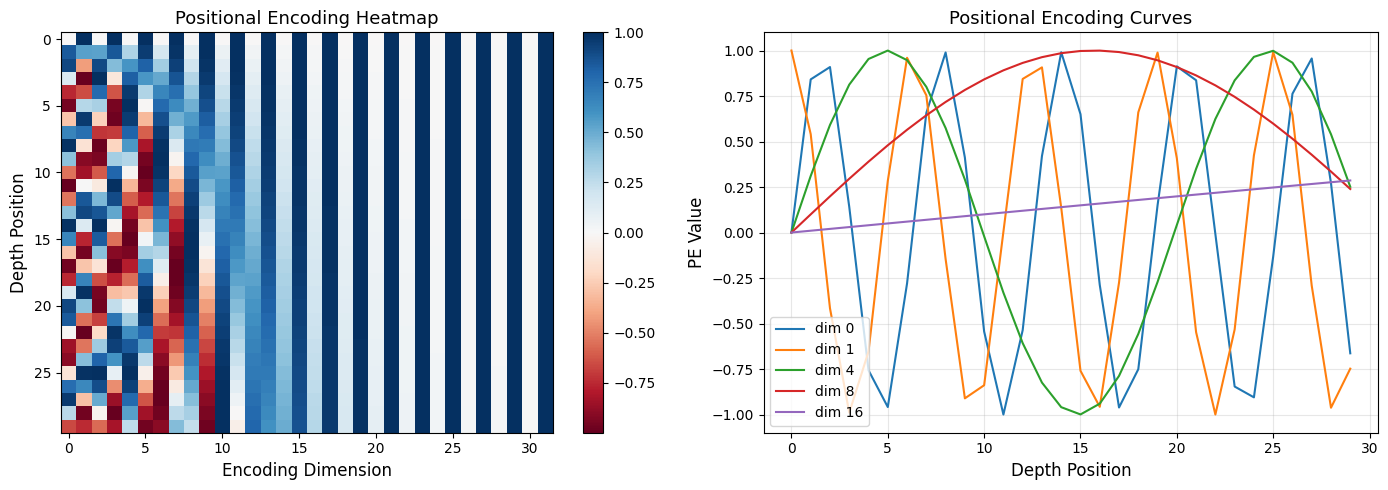

Low dimensions oscillate fast (fine position detail).
High dimensions oscillate slowly (coarse position detail).
Together they give each position a unique encoding vector.


In [4]:
# ───────────────────────────────────────────────────────
# POSITIONAL ENCODING
# ───────────────────────────────────────────────────────

class PositionalEncoding(nn.Module):
    """Sinusoidal positional encoding for sequences."""
    
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model)
        )
        
        pe[:, 0::2] = torch.sin(position * div_term)   # even indices
        pe[:, 1::2] = torch.cos(position * div_term)   # odd indices
        
        pe = pe.unsqueeze(0)  # (1, max_len, d_model)
        self.register_buffer('pe', pe)
    
    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

# Visualize positional encoding
d_model = 32
pe_module = PositionalEncoding(d_model, max_len=30)
pe_values = pe_module.pe[0, :30, :].numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

im = axes[0].imshow(pe_values, cmap='RdBu', aspect='auto')
plt.colorbar(im, ax=axes[0])
axes[0].set_xlabel('Encoding Dimension', fontsize=12)
axes[0].set_ylabel('Depth Position', fontsize=12)
axes[0].set_title('Positional Encoding Heatmap', fontsize=13)

for dim in [0, 1, 4, 8, 16]:
    axes[1].plot(range(30), pe_values[:, dim], linewidth=1.5, label=f'dim {dim}')
axes[1].set_xlabel('Depth Position', fontsize=12)
axes[1].set_ylabel('PE Value', fontsize=12)
axes[1].set_title('Positional Encoding Curves', fontsize=13)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Low dimensions oscillate fast (fine position detail).")
print("High dimensions oscillate slowly (coarse position detail).")
print("Together they give each position a unique encoding vector.")

---

## Part 4: Multi-Head Attention

Multi-head attention runs **multiple attention heads in parallel**, each attending to different aspects:

$$\text{MultiHead}(Q, K, V) = \text{Concat}(\text{head}_1, ..., \text{head}_h) W^O$$

In geotechnical terms: one head might attend to tip resistance patterns, another to friction patterns.

In [5]:
# ───────────────────────────────────────────────────────
# MULTI-HEAD ATTENTION IN PYTORCH
# ───────────────────────────────────────────────────────

# PyTorch provides nn.MultiheadAttention
d_model = 32
n_heads = 4

mha = nn.MultiheadAttention(embed_dim=d_model, num_heads=n_heads, batch_first=True)

# Test with random input
test_input = torch.randn(1, 30, d_model)  # (batch=1, seq_len=30, d_model=32)

attn_output, attn_weights_mha = mha(test_input, test_input, test_input)

print(f"Input shape:          {test_input.shape}")
print(f"Attention output:     {attn_output.shape}")
print(f"Attention weights:    {attn_weights_mha.shape}  (averaged over heads)")
print(f"\nNumber of heads: {n_heads}")
print(f"Dimension per head: {d_model // n_heads}")
print(f"Total MHA parameters: {sum(p.numel() for p in mha.parameters()):,}")

Input shape:          torch.Size([1, 30, 32])
Attention output:     torch.Size([1, 30, 32])
Attention weights:    torch.Size([1, 30, 30])  (averaged over heads)

Number of heads: 4
Dimension per head: 8
Total MHA parameters: 4,224


---

## Part 5: Transformer Encoder for CPT Classification

In [6]:
# ───────────────────────────────────────────────────────
# TRANSFORMER ENCODER MODEL
# ───────────────────────────────────────────────────────

class CPTTransformer(nn.Module):
    """Transformer Encoder for CPT soil classification."""
    
    def __init__(self, n_features=4, d_model=32, n_heads=4,
                 n_layers=2, n_classes=3, dropout=0.1):
        super().__init__()
        
        # Input projection: features -> d_model
        self.input_proj = nn.Linear(n_features, d_model)
        
        # Positional encoding
        self.pos_encoder = PositionalEncoding(d_model)
        
        # Transformer encoder layers
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_model * 4,
            dropout=dropout,
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        
        # Classification head (per-position)
        self.classifier = nn.Linear(d_model, n_classes)
    
    def forward(self, x):
        """
        x: (batch, seq_len, n_features)
        Returns: (batch, seq_len, n_classes)
        """
        x = self.input_proj(x)        # (B, S, d_model)
        x = self.pos_encoder(x)        # add positional encoding
        x = self.transformer(x)        # self-attention layers
        x = self.classifier(x)         # (B, S, n_classes)
        return x

model = CPTTransformer(n_features=4, d_model=32, n_heads=4, n_layers=2, n_classes=3)
print(model)
print(f"\nTotal parameters: {sum(p.numel() for p in model.parameters()):,}")

CPTTransformer(
  (input_proj): Linear(in_features=4, out_features=32, bias=True)
  (pos_encoder): PositionalEncoding()
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
        )
        (linear1): Linear(in_features=32, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=32, bias=True)
        (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (classifier): Linear(in_features=32, out_features=3, bias=True)
)

Total parameters: 25,667


---

## Part 6: Train the Transformer

In [7]:
# ───────────────────────────────────────────────────────
# PREPARE DATA AND TRAIN
# ───────────────────────────────────────────────────────

# Normalize features
X_mean = X_data.mean(axis=(0, 1))
X_std = X_data.std(axis=(0, 1))
X_norm = (X_data - X_mean) / (X_std + 1e-8)

# Train/test split
n_train = 160
X_train = torch.tensor(X_norm[:n_train], dtype=torch.float32)
y_train = torch.tensor(y_data[:n_train], dtype=torch.long)
X_test = torch.tensor(X_norm[n_train:], dtype=torch.float32)
y_test = torch.tensor(y_data[n_train:], dtype=torch.long)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# Training
model = CPTTransformer(n_features=4, d_model=32, n_heads=4, n_layers=2, n_classes=3)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

n_epochs = 100
train_losses, test_accs = [], []

for epoch in range(n_epochs):
    model.train()
    optimizer.zero_grad()
    
    logits = model(X_train)  # (B, S, 3)
    loss = criterion(logits.reshape(-1, 3), y_train.reshape(-1))
    loss.backward()
    optimizer.step()
    
    train_losses.append(loss.item())
    
    # Test accuracy
    if epoch % 10 == 0 or epoch == n_epochs - 1:
        model.eval()
        with torch.no_grad():
            test_logits = model(X_test)
            preds = test_logits.argmax(dim=-1)
            acc = (preds == y_test).float().mean().item()
            test_accs.append(acc)
            print(f"Epoch {epoch:3d}/{n_epochs} | Loss: {loss.item():.4f} | Test Acc: {acc:.4f}")

print(f"\nFinal test accuracy: {test_accs[-1]:.4f}")

Train: torch.Size([160, 30, 4]), Test: torch.Size([40, 30, 4])


Epoch   0/100 | Loss: 1.1297 | Test Acc: 0.4217


Epoch  10/100 | Loss: 0.6001 | Test Acc: 0.8058


Epoch  20/100 | Loss: 0.3668 | Test Acc: 0.8833


Epoch  30/100 | Loss: 0.2519 | Test Acc: 0.9158


Epoch  40/100 | Loss: 0.1870 | Test Acc: 0.9400


... (2 outputs left out)

Epoch  70/100 | Loss: 0.1039 | Test Acc: 0.9667


Epoch  80/100 | Loss: 0.0942 | Test Acc: 0.9700


Epoch  90/100 | Loss: 0.0827 | Test Acc: 0.9717


Epoch  99/100 | Loss: 0.0776 | Test Acc: 0.9758

Final test accuracy: 0.9758


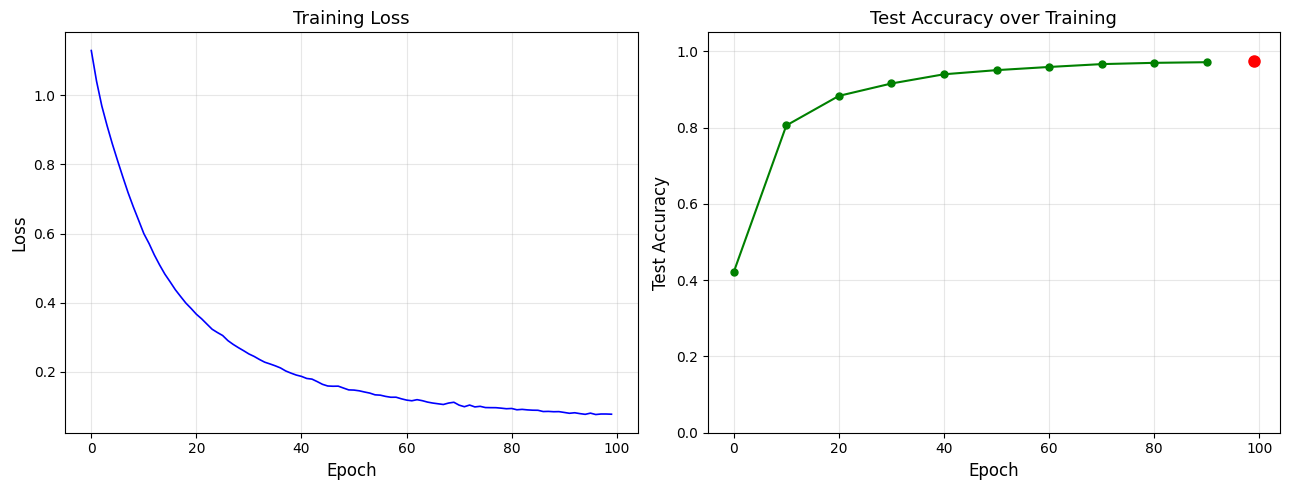

In [8]:
# ───────────────────────────────────────────────────────
# TRAINING CURVES
# ───────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(train_losses, 'b-', linewidth=1.2)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].set_title('Training Loss', fontsize=13)
axes[0].grid(True, alpha=0.3)

axes[1].plot(range(0, n_epochs, 10), test_accs[:-1], 'go-', linewidth=1.5, markersize=5)
axes[1].plot(n_epochs - 1, test_accs[-1], 'ro', markersize=8)
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Test Accuracy', fontsize=12)
axes[1].set_title('Test Accuracy over Training', fontsize=13)
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim(0, 1.05)

plt.tight_layout()
plt.show()

---

## Part 7: Attention Weight Interpretation

One of the biggest advantages of Transformers: we can **visualize attention weights** to understand
which depths the model considers most important for classifying each layer.

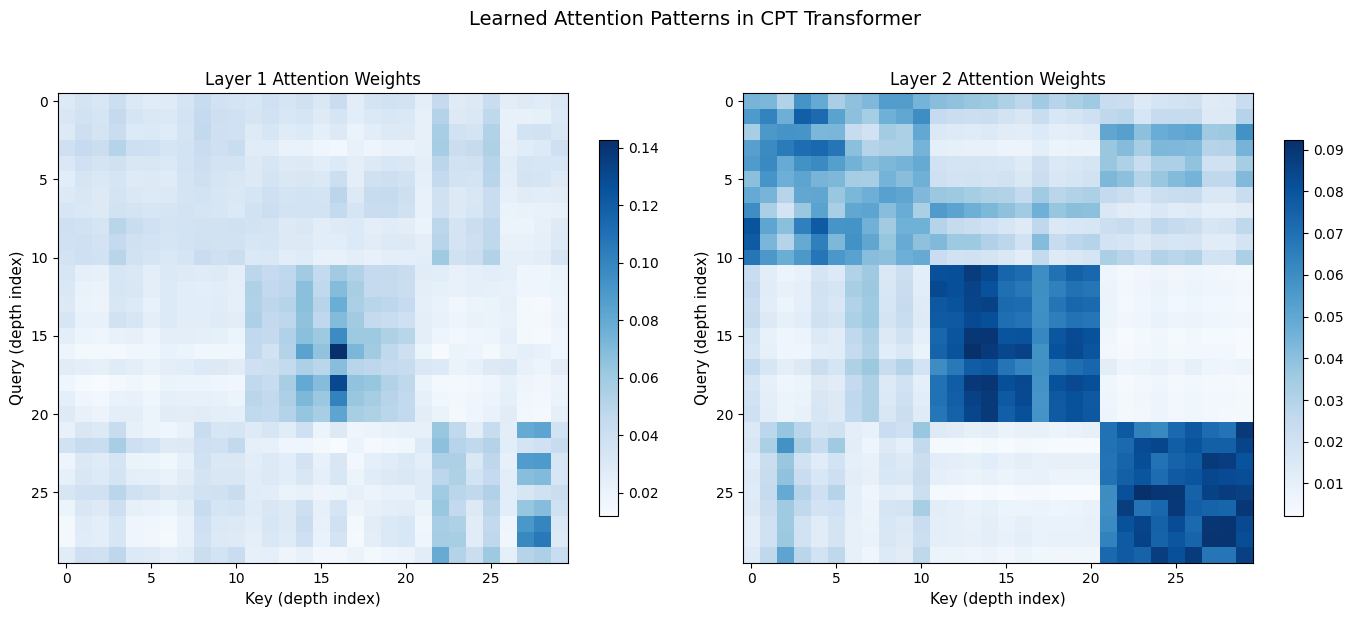

Bright spots show which depths attend to each other.
Diagonal = self-attention (each depth attends to itself).
Off-diagonal = cross-depth attention (context from other layers).


In [9]:
# ───────────────────────────────────────────────────────
# EXTRACT AND VISUALIZE ATTENTION WEIGHTS
# ───────────────────────────────────────────────────────

# nn.TransformerEncoderLayer calls its attention with need_weights=False,
# so a forward hook would only receive None. Instead we walk through the
# layers ourselves and ask each attention block for its weights.
attention_maps = []

model.eval()
with torch.no_grad():
    sample_input = X_test[0:1]                                   # (1, 30, 4)
    h = model.pos_encoder(model.input_proj(sample_input))        # (1, 30, d_model)
    for layer in model.transformer.layers:
        _, attn = layer.self_attn(h, h, h, need_weights=True,
                                  average_attn_weights=True)     # (1, 30, 30)
        attention_maps.append(attn)
        h = layer(h)                                             # output feeds next layer

# Plot attention maps per layer
n_attn_layers = len(attention_maps)
fig, axes = plt.subplots(1, n_attn_layers, figsize=(7 * n_attn_layers, 6))
if n_attn_layers == 1:
    axes = [axes]

for i, attn in enumerate(attention_maps):
    attn_np = attn[0].numpy()  # (seq_len, seq_len)
    im = axes[i].imshow(attn_np, cmap='Blues', aspect='auto')
    plt.colorbar(im, ax=axes[i], shrink=0.8)
    axes[i].set_xlabel('Key (depth index)', fontsize=11)
    axes[i].set_ylabel('Query (depth index)', fontsize=11)
    axes[i].set_title(f'Layer {i+1} Attention Weights', fontsize=12)

plt.suptitle('Learned Attention Patterns in CPT Transformer', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("Bright spots show which depths attend to each other.")
print("Diagonal = self-attention (each depth attends to itself).")
print("Off-diagonal = cross-depth attention (context from other layers).")

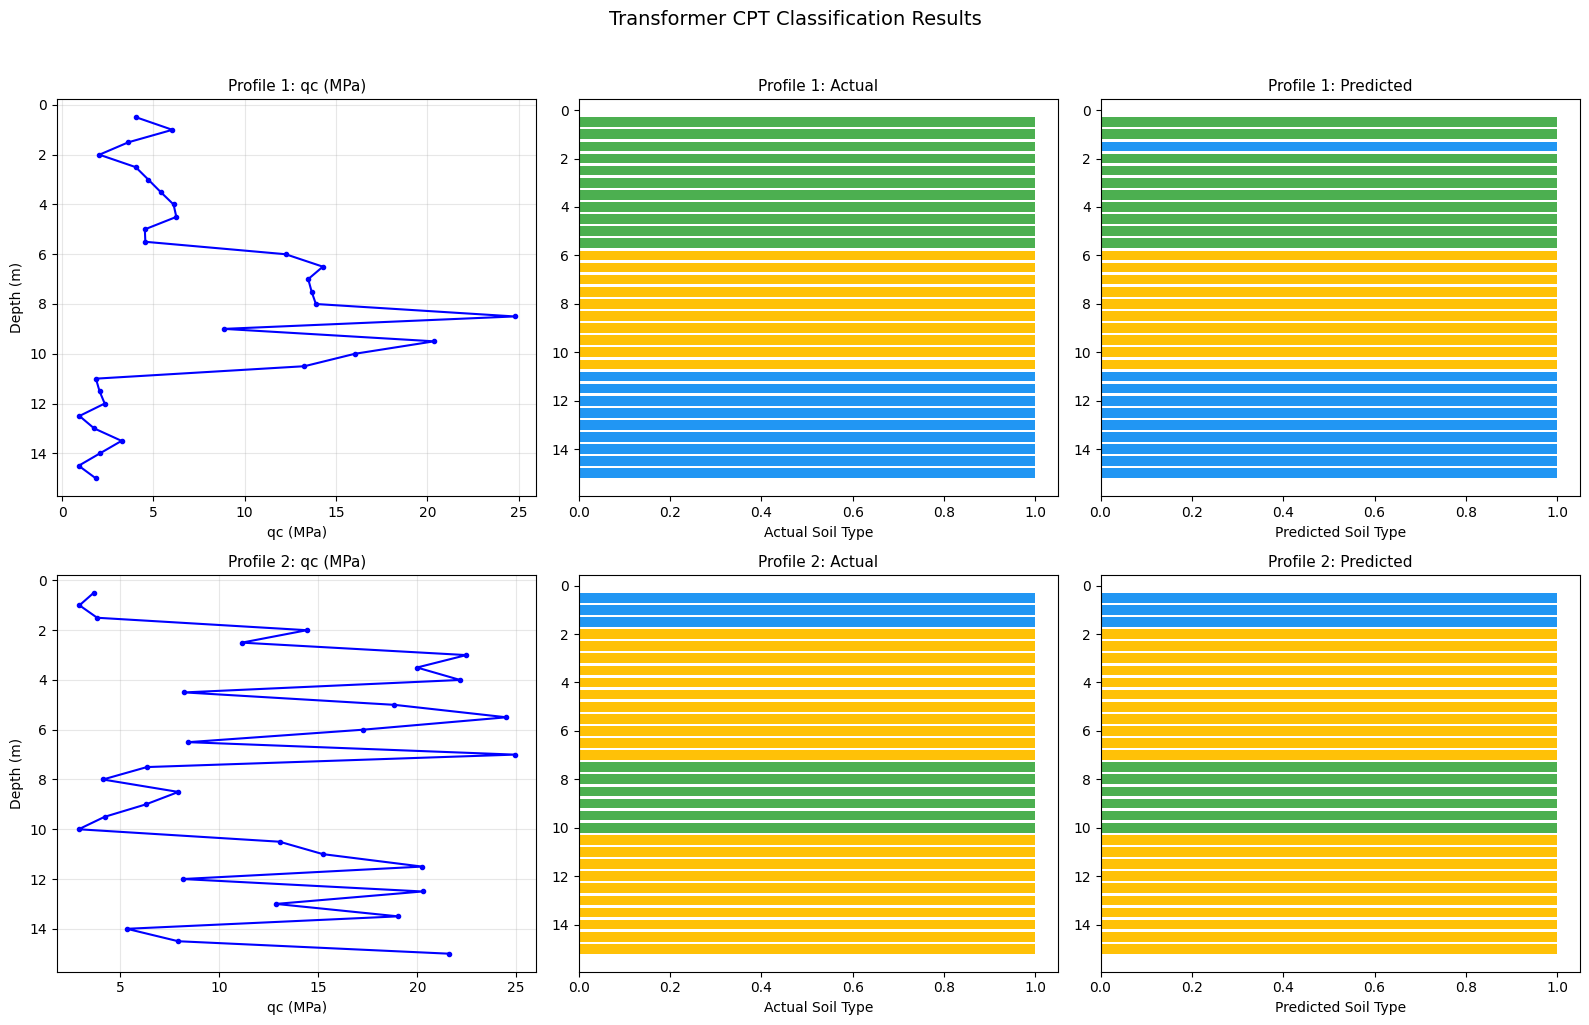

In [10]:
# ───────────────────────────────────────────────────────
# VISUALIZE PREDICTION ON A TEST PROFILE
# ───────────────────────────────────────────────────────

model.eval()
with torch.no_grad():
    test_logits = model(X_test)
    test_preds = test_logits.argmax(dim=-1).numpy()

# Show a few profiles
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
soil_names_list = ['Clay', 'Sand', 'Silt']

for idx, ax_row in enumerate(axes):
    for col, (ax, title) in enumerate(zip(ax_row, ['qc (MPa)', 'Actual', 'Predicted'])):
        if col == 0:
            ax.plot(X_data[n_train + idx, :, 0], depths, 'b-o', markersize=3)
            ax.set_xlabel('qc (MPa)', fontsize=10)
            ax.set_ylabel('Depth (m)', fontsize=10)
            ax.invert_yaxis()
            ax.grid(True, alpha=0.3)
        elif col == 1:
            for d_idx in range(len(depths)):
                ax.barh(depths[d_idx], 1, height=0.4,
                        color=soil_colors[y_data[n_train + idx, d_idx]])
            ax.set_xlabel('Actual Soil Type', fontsize=10)
            ax.invert_yaxis()
        else:
            for d_idx in range(len(depths)):
                ax.barh(depths[d_idx], 1, height=0.4,
                        color=soil_colors[test_preds[idx, d_idx]])
            ax.set_xlabel('Predicted Soil Type', fontsize=10)
            ax.invert_yaxis()
        ax.set_title(f'Profile {idx+1}: {title}', fontsize=11)

plt.suptitle('Transformer CPT Classification Results', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

---

## Practice Exercises

### Exercise 1: Vary Number of Heads
Try `n_heads=1` vs `n_heads=8`. How does the number of heads affect accuracy and attention patterns?

### Exercise 2: Longer Sequences
Generate profiles with `seq_len=60` (deeper boreholes). Does the Transformer still perform well?

### Exercise 3: Compare with LSTM
Build a simple LSTM classifier for the same task. Compare accuracy, training speed, and interpretability.

In [11]:
# EXERCISE SPACE

# Exercise 1: Try different head counts
# model_1h = CPTTransformer(n_heads=1)
# model_8h = CPTTransformer(n_heads=8)

# Exercise 2: Longer sequences
# X_long, y_long = generate_cpt_profiles(seq_len=60)

# Exercise 3: LSTM comparison
# class CPTLSTM(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.lstm = nn.LSTM(4, 32, batch_first=True, bidirectional=True)
#         self.fc = nn.Linear(64, 3)
#     def forward(self, x):
#         out, _ = self.lstm(x)
#         return self.fc(out)

---

## Key Takeaways

1. **Self-attention lets every position attend to every other position.** Unlike RNNs/LSTMs that process sequentially, Transformers see the entire CPT profile at once.

2. **Positional encoding injects depth information.** Without it, the Transformer cannot distinguish depth 1m from depth 10m since attention is permutation-invariant.

3. **Multi-head attention captures diverse patterns.** Different heads can attend to different property relationships (e.g., qc-based vs friction-based patterns).

4. **Attention weights are interpretable.** We can visualize which depths influence the classification at each point, providing geotechnical insight.

5. **Transformers are powerful but need enough data.** They have more parameters than LSTMs and benefit from larger datasets.

---

## How This Connects to ML

| Transformer Concept | Geotechnical Interpretation |
|---|---|
| Self-attention | Each soil layer considers all other layers |
| Positional encoding | Depth information in the borehole |
| Multi-head attention | Multiple property relationships checked simultaneously |
| Attention weights | Which depths most influence classification |
| Transformer encoder | Full-profile soil classifier |

**Transformers are the backbone of modern AI** — tomorrow we explore TabNet for tabular geotechnical data.

---

*Day 080 of 100 — Attention is all you need... and some good soil data!*